In [110]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from functools import reduce
from itertools import product
import calendar

In [111]:

BASE_DIR = "clean_dataset"

table_date = [
    'sales_pipeline'
]

date_columns = {
    name: ['engage_date', 'close_date']
    for name in table_date}


dfs = {}

for file in os.listdir(BASE_DIR):

    if file.endswith(".csv"):

        path = os.path.join(BASE_DIR, file)
        name = file.replace(".csv", "")

        dates = date_columns.get(name, None)

     
        df = pd.read_csv(
            path,
            parse_dates=dates
        )

        dfs[name] = df



## Exploratory Data

account :85
sector  : 10 ['technolgy', 'medical', 'retail', 'software', 'entertainment', 'marketing', 'telecommunications', 'finance', 'employment', 'services']
year_established : min (1979) - max(2017)
revenue : min (4.54) - max(11698.03)
employees : min (9) - max(34288)
office_location  : 15 ['United States', 'Kenya', 'Philipines', 'Japan', 'Italy', 'Norway', 'Korea', 'Jordan', 'Brazil', 'Germany', 'Panama', 'Belgium', 'Romania', 'Poland', 'China']
subsidiary_of  : 8 ['Unknown', 'Acme Corporation', 'Massive Dynamic', 'Bubba Gump', 'Inity', 'Sonron', 'Golddex', 'Warephase']


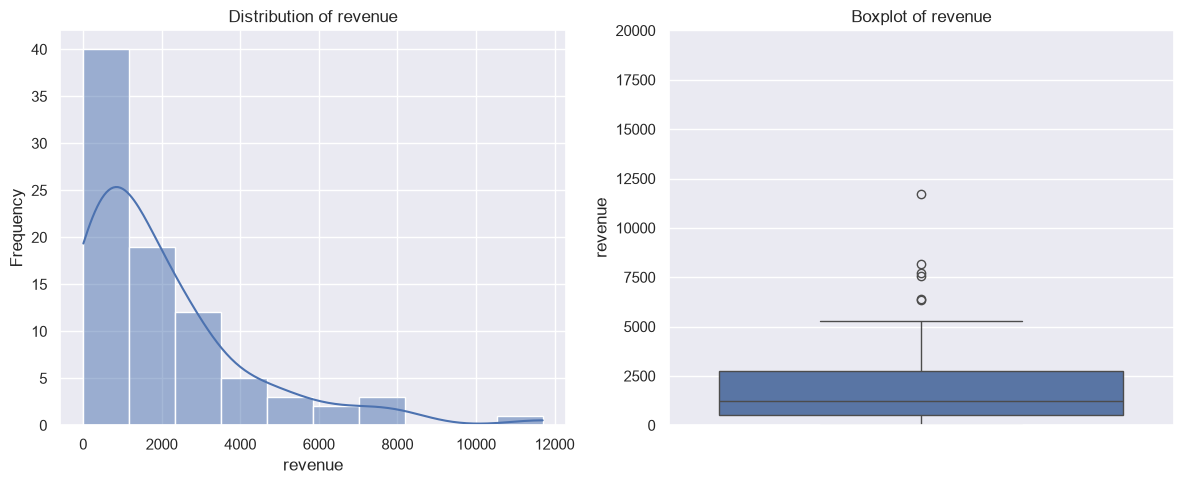

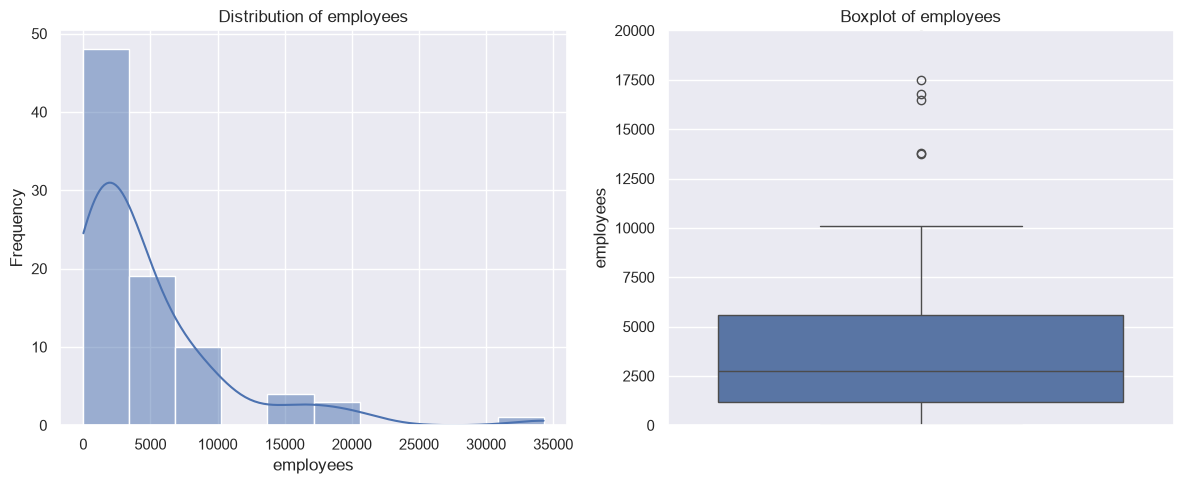

In [112]:
df_accounts = dfs['accounts']
columns = df_accounts.columns

for column in columns :
    if column == "account" :
        print(f'{column} :{df_accounts[column].nunique()}')
    elif column in ['sector', 'office_location', 'subsidiary_of']:
        print(f"{column}  : {df_accounts[column].nunique()} {list(df_accounts[column].unique())}")
    else :
        print(f'{column} : min ({df_accounts[column].min()}) - max({df_accounts[column].max()})')

num_columns = ['revenue', 'employees']

for column in num_columns:
    data = df_accounts
    sns.set_style("darkgrid")
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    sns.histplot(
        data=data,
        x=column,
        bins=10,
        kde=True,
        ax=axes[0]
    )
    axes[0].set_title(f'Distribution of {column}')
    axes[0].set_xlabel(f'{column}')
    axes[0].set_ylabel('Frequency')
    plt.ylim(0, 20000) 
    
    sns.boxplot(
        data=data, 
        y=column, 
        ax=axes[1]
    )
    axes[1].set_title(f'Boxplot of {column}')
    axes[1].set_ylabel(f'{column}') 

    plt.tight_layout()
    plt.show()

Mayoritas target klien kita (75%) merupakan perusahaan skala kecil hingga menengah dengan pendapatan tahunan di bawah $2.8M dan jumlah karyawan di bawah 5.500 orang. Hanya sedikit perusahaan yang beroperasi sebagai enterprise raksasa dengan pendapatan melebihi $5M atau karyawan di atas 10.000 orang

In [113]:
df_products = dfs['products']
df_sales_pipeline = dfs['sales_pipeline']
df_sales_pipeline_Won = df_sales_pipeline[df_sales_pipeline['deal_stage']=='Won']
df_sales_pipeline_Lost = df_sales_pipeline[df_sales_pipeline['deal_stage']=='Lost']


# Analysis Data

##
**Account Performance Analysis**

>>Berapa total SQL yang tersedia?

>>Berapa % dari Account yang kemudian memiliki opportunity?

>>Berapa average opportunity yang di offer untuk tiap SQL nya?

>>Berapa dari SQL yang ada yang kemudian menjad Client?

In [114]:
print(f"total accounts :{df_accounts['account'].nunique()}")
print(f"total account to opportunity : {df_sales_pipeline['account'].nunique()}")
print(f"convertion rate account to opportunity : {round((df_sales_pipeline[df_sales_pipeline['account']!='Unidentified']['account'].nunique() / df_accounts['account'].nunique()) * 100, 0)}%")
print(f"average opportunity offered by accoount : {round((df_sales_pipeline['opportunity_id'].count()/df_sales_pipeline['account'].nunique()),0)}")
print(f"total win account : {df_sales_pipeline_Won['account'].nunique()}")
print(f"account to client rate : {round((df_sales_pipeline_Won['account'].nunique()/df_sales_pipeline['account'].nunique())*100,0)}%")

total accounts :85
total account to opportunity : 86
convertion rate account to opportunity : 100.0%
average opportunity offered by accoount : 102.0
total win account : 85
account to client rate : 99.0%


>> Apakah setiap bulan ada pertambahan client baru?

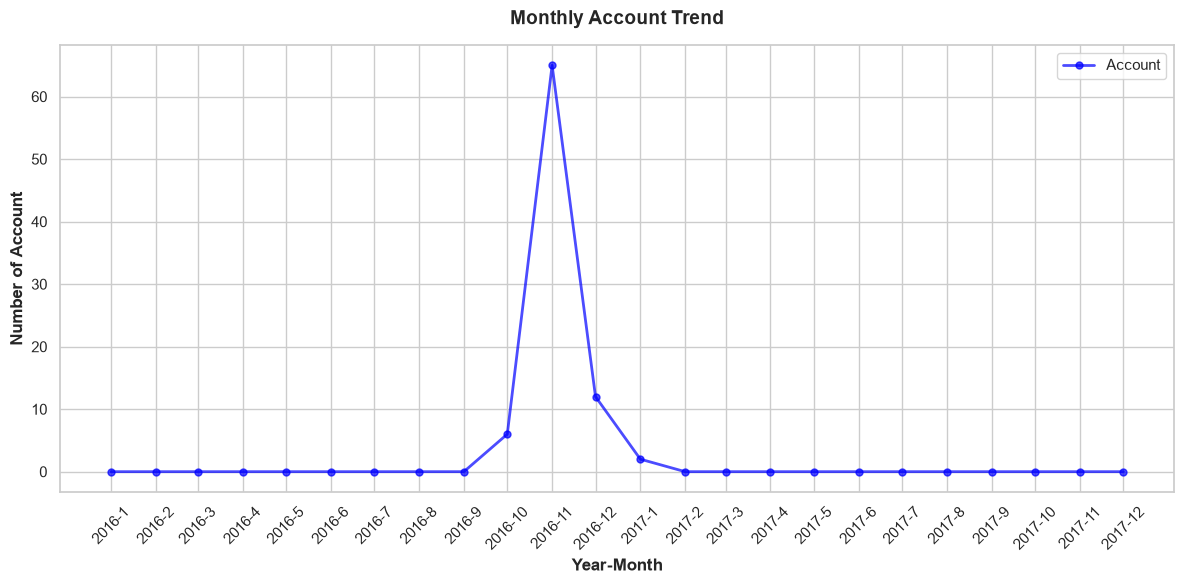

In [115]:
df_sales_pipeline_all_eng = df_sales_pipeline[~df_sales_pipeline['engage_date'].isna()]

data = []
months = np.arange(1, 13)
years = df_sales_pipeline_all_eng['engage_date'].dt.year.dropna().unique()

for month, year in product(months, years):
    start_date = pd.Timestamp(f'{year}-{month}-1')
    last_day = calendar.monthrange(year,month)[1]
    end_date = pd.Timestamp(year,month,last_day)

    hist_acc = df_sales_pipeline_all_eng[(df_sales_pipeline_all_eng['engage_date']<start_date)]['account'].unique()

    monthly_eng_account = df_sales_pipeline_all_eng[
        (df_sales_pipeline_all_eng['engage_date']>=start_date)&
        (df_sales_pipeline_all_eng['engage_date']<=end_date)]['account'].unique()
    
    new_engg_acc = np.setdiff1d(monthly_eng_account,hist_acc)

    data.append(
        {'year' : year,
         'month': month,
         'account': len(new_engg_acc)}
    )

data_eng_acc = pd.DataFrame(data)
data_eng_acc['year-month'] = (
    pd.to_datetime(data_eng_acc['year']
                   .astype(str)+'-'+data_eng_acc['month']
                   .astype(str)
                   ,format = '%Y-%m')
)

data_eng_acc['y-m']= (
    data_eng_acc['year']
    .astype(str)+"-"+data_eng_acc['month']
    .astype(str)
)

data_eng_acc = data_eng_acc.sort_values('year-month')

plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

plt.plot(
    data_eng_acc['year-month'],
    data_eng_acc['account'],
    color='blue',
    linestyle='-',
    linewidth=2,
    marker='o',
    markersize=5,
    label='Account',
    alpha=0.7
)

plt.xlabel("Year-Month", fontsize=12, fontweight="bold")
plt.ylabel("Number of Account", fontsize=12, fontweight="bold")

plt.title(
    "Monthly Account Trend",
    fontsize=14,
    fontweight="bold",
    pad=15
)

for x, y in enumerate(data_eng_acc['account']):
    plt.annotate(
        str(y),
        (x, y),
        textcoords='offset points',
        xytext=(0, 8),
        ha='center',
        fontsize=9,
        fontweight='bold'
    )
    
plt.xticks(
    ticks=data_eng_acc['year-month'],
    labels=data_eng_acc['y-m'],
    rotation=45
)
    

plt.legend()
plt.tight_layout()
plt.show()



Berdasarkan data Engaging by Account, account mulai memasuki tahap Engaging pada Q4 2016, dan seluruh account telah tercatat memasuki tahap Engaging pada Q1 2017.

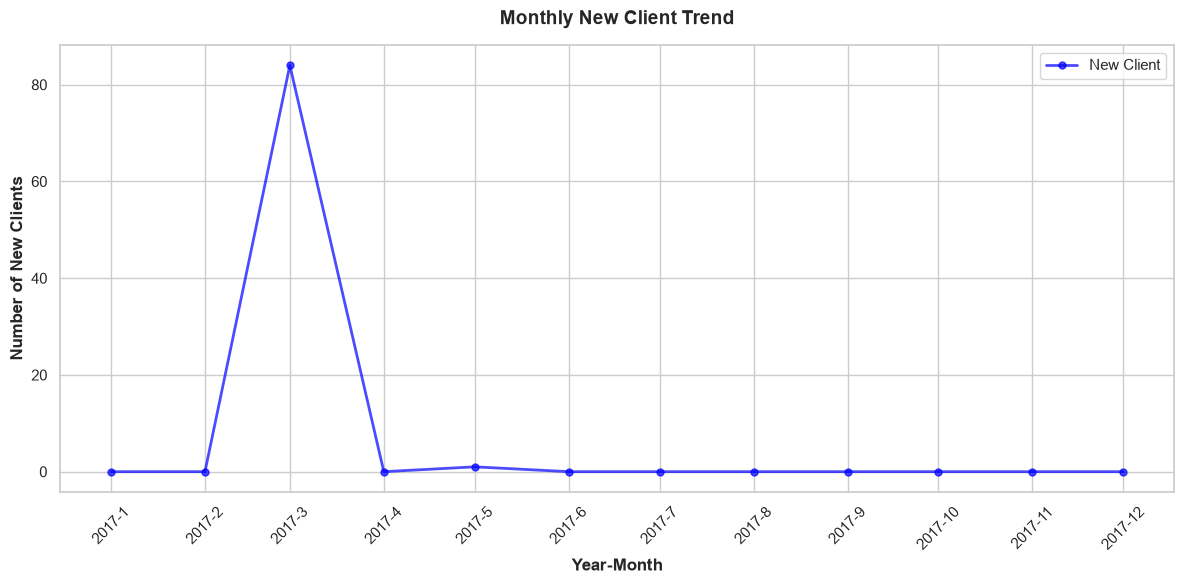

,y-m,new_client,acquitition_rate
0,2017-1,0,0.0
1,2017-2,0,0.0
2,2017-3,84,99.0
3,2017-4,0,0.0
4,2017-5,1,1.0
5,2017-6,0,0.0
6,2017-7,0,0.0
7,2017-8,0,0.0
8,2017-9,0,0.0
9,2017-10,0,0.0


In [116]:
data = []
months = np.arange(1, 13)
years = df_sales_pipeline_Won['close_date'].dt.year.dropna().unique()

for month, year in product(months, years):

    last_day = calendar.monthrange(year, month)[1]
    start_date = pd.Timestamp(f'{year}-{month}-1')
    end_date = pd.Timestamp(year, month, last_day)

    old_client = df_sales_pipeline_Won[df_sales_pipeline_Won['close_date']<start_date]['account'].unique()

    month_client = df_sales_pipeline_Won[
        (df_sales_pipeline_Won['close_date']>=start_date)&
        (df_sales_pipeline_Won['close_date']<=end_date)]['account'].unique()
    
    newest_client = np.setdiff1d(month_client,old_client)
    

    data.append(
        {'year' : year,
         'month': month,
         'new_client' : len(newest_client),
         'accounts': list(newest_client)}
    )

df_monthly_new_client = pd.DataFrame(data)
df_monthly_new_client['year-month'] = (
    pd.to_datetime(
        df_monthly_new_client['year']
        .astype(str)+'-'+df_monthly_new_client['month']
        .astype(str),format = '%Y-%m')
)

df_monthly_new_client['y-m'] = (
    df_monthly_new_client['year']
    .astype(str)+"-"+df_monthly_new_client['month']
    .astype(str)
)

df_monthly_new_client['acquitition_rate'] = (
    round(
        (df_monthly_new_client['new_client']/
         (df_sales_pipeline_Won['account']
          .nunique()
          )
        *100)
        ,)
)

monthly_client_ac = (
    df_monthly_new_client[
        ['y-m',
         'new_client',
         'acquitition_rate']
         ]
)

plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

plt.plot(
    df_monthly_new_client['year-month'],
    df_monthly_new_client['new_client'],
    color='blue',
    linestyle='-',
    linewidth=2,
    marker='o',
    markersize=5,
    label='New Client',
    alpha=0.7
)

plt.xlabel("Year-Month", fontsize=12, fontweight="bold")
plt.ylabel("Number of New Clients", fontsize=12, fontweight="bold")

plt.title(
    "Monthly New Client Trend",
    fontsize=14,
    fontweight="bold",
    pad=15
)
    
plt.xticks(
    ticks=df_monthly_new_client['year-month'],
    labels=df_monthly_new_client['y-m'],
    rotation=45
)
plt.legend()
plt.tight_layout()
plt.show()

display(monthly_client_ac)


berdasarkan data monthly new client trend diatas, 99% account berhasil diubah menjadi client pada bulan ke 3, sementara 1% diubah menjadi client di bulan ke 5

In [117]:
first_eng_acc = (
    df_sales_pipeline_all_eng
    .groupby('account')
    .agg(first_engage = ('engage_date','min'))
    .reset_index()
)

first_win_acc = (
    df_sales_pipeline_Won
    .groupby('account')
    .agg(first_win = ('close_date','min'))
    .reset_index()
)

first_date_acc = (
    pd.merge(
        first_eng_acc,
        first_win_acc,
        on ='account',
        how='outer')
)

first_date_acc['day_diff'] = (
    first_date_acc['first_win']-
    first_date_acc['first_engage']
)


print(f"average different days from first engaged opportunity to first win : {round(((first_date_acc['day_diff'].dt.days).mean()),0)}")
print(f"The shortes days from first engaged opportunity to first win : {(first_date_acc['day_diff'].dt.days).min()}")
print(f"The longest days from first engaded opportunity to first win : {(first_date_acc['day_diff'].dt.days).max()}")
display(first_date_acc.sort_values('day_diff',ascending=True))

average different days from first engaged opportunity to first win : 107.0
The shortes days from first engaged opportunity to first win : 57
The longest days from first engaded opportunity to first win : 136


,account,first_engage,first_win,day_diff
49,Newex,2017-01-07,2017-03-05,57 days
66,Streethex,2016-12-26,2017-03-16,80 days
67,Sumace,2016-12-12,2017-03-02,80 days
34,Hottechi,2016-12-10,2017-03-02,82 days
32,Groovestreet,2016-12-19,2017-03-16,87 days
...,...,...,...,...
10,Codehow,2016-10-25,2017-03-01,127 days
37,Isdom,2016-10-25,2017-03-01,127 days
33,Hatfan,2016-10-25,2017-03-02,128 days
8,Cancity,2016-10-20,2017-03-01,132 days


rata-rata perbedaan hari dari pertama kali account menerima enggaed opportunity menuju first win oppportunity adalah 107 hari, dengan yang paling ceapt adalah 57 hari dan paling lama adalah 136 hari

In [118]:
df_sales_pipeline_closed = (
    df_sales_pipeline[~df_sales_pipeline['close_date']
                      .isna()]
)

df_sales_pipeline_Pros = (
    df_sales_pipeline[df_sales_pipeline['deal_stage']=='Prospecting']
)

df_sales_pipeline_engaging = (
    df_sales_pipeline[df_sales_pipeline['deal_stage']=='Engaging']
)

df_sales_pipeline_Won['diff_days'] = (
    (df_sales_pipeline_Won['close_date']-
     df_sales_pipeline_Won['engage_date'])
     .dt.days
)

duration_to_win = (
    df_sales_pipeline_Won
    .groupby('account')
    .agg(avg_duration_to_win = ('diff_days','mean'))
    .reset_index()
)

duration_to_win['avg_duration_to_win'] = round(duration_to_win['avg_duration_to_win'],)

df_sales_pipeline_closed['diff_days'] = (
    (df_sales_pipeline_closed['close_date']-
     df_sales_pipeline_closed['engage_date'])
     .dt.days
)

duration_to_close = (
    df_sales_pipeline_closed
    .groupby('account')
    .agg(avg_duration_to_close = ('diff_days','mean'))
    .reset_index()
)

duration_to_close['avg_duration_to_close'] = round(duration_to_close['avg_duration_to_close'],)

df_acc_opp = (
    df_sales_pipeline[df_sales_pipeline['account']!='Unidentified']
    .groupby('account')
    .agg(total_opportunity = ('opportunity_id','count'))
    .reset_index()
)

df_acc_opp_pros = (
    df_sales_pipeline_Pros[df_sales_pipeline_Pros['account']!='Unidentified']
    .groupby('account')
    .agg(prospecting = ('opportunity_id','count'))
    .reset_index()
)

df_acc_opp_eng = (
    df_sales_pipeline_engaging
    .groupby('account')
    .agg(engaging = ('opportunity_id','count'))
    .reset_index()
)

df_acc_opp_won = (
    df_sales_pipeline_Won
    .groupby('account')
    .agg(won= ('opportunity_id','count'), 
         account_value = ('close_value','sum'))
    .reset_index()
)

df_acc_opp_lost = (
    df_sales_pipeline_Lost
    .groupby('account')
    .agg(lost = ('opportunity_id','count'))
    .reset_index()
)

data_accounts = [
    df_acc_opp,
    df_acc_opp_pros,
    df_acc_opp_eng,
    df_acc_opp_won,
    df_acc_opp_lost,
    duration_to_close,
    duration_to_win,
    first_date_acc
]

df_accounts_summary = reduce(
    lambda df1, df2: pd.merge(
        df1, df2,
        on='account',
        how='outer'
    ),
    data_accounts
)
df_accounts_summary['win_rate'] = (
    round(
        (
            (df_accounts_summary['won']/
             (df_accounts_summary['won']+df_accounts_summary['lost']))
             *100),
             )
)

df_accounts_summary = df_accounts_summary.fillna(0)

print(f" Average duration of account to close the opportunity : {round((df_accounts_summary['avg_duration_to_close'].mean()),0)}")
print(f" Average duration of account to win the opportunity : {round((df_accounts_summary['avg_duration_to_win'].mean()),0)}")
print(f" The shortes days to win the oppportunity : {min(df_accounts_summary['avg_duration_to_win'])}")
print(f" The longest days to win the oppportunity : {max(df_accounts_summary['avg_duration_to_win'])}")
print(f" Average opportunity win rate : {round((df_accounts_summary['win_rate'].mean()),0)}")
display(df_accounts_summary.sort_values(['account_value','win_rate','avg_duration_to_win'],ascending=[False,False,True]).head())


 Average duration of account to close the opportunity : 48.0
 Average duration of account to win the opportunity : 52.0
 The shortes days to win the oppportunity : 38.0
 The longest days to win the oppportunity : 74.0
 Average opportunity win rate : 63.0


,account,total_opportunity,prospecting,engaging,won,account_value,lost,avg_duration_to_close,avg_duration_to_win,first_engage,first_win,day_diff,win_rate
40,Kan-code,206,1.0,18,115,341455.0,72,47.0,51.0,2016-11-21,2017-03-04,103 days,61.0
42,Konex,190,3.0,16,108,269245.0,63,44.0,48.0,2016-11-24,2017-03-13,109 days,63.0
11,Condax,183,3.0,21,105,206410.0,54,49.0,58.0,2016-11-27,2017-03-03,96 days,66.0
9,Cheers,114,1.0,23,57,198020.0,33,47.0,48.0,2016-11-01,2017-03-05,124 days,63.0
34,Hottechi,209,2.0,14,111,194957.0,82,48.0,56.0,2016-12-10,2017-03-02,82 days,58.0


rata-rata closing dari seluruh client adalah 48 hari, sementara rata-rata closing dengan status win adalah 52 hari, dengan durasi client menutup opportunity dengan status win tercepat adalah 38  hari dan paling lama adalah 74 hari. Sementara untuk rata-rata win rate opportunitinya adalah sebesar 49%

Kan-Code menjadi account dengan kombinasi value,dan win rate tinggi dan rata-rata durasi close to win rendah di urutan pertama dibandingkan accont lainnya, sementara Golddex menjadi yang paling rendah

Semua account berakhir menjadi client dengan durasi proses yang berbeda-beda tiap accountya, Hal ini menujukkan bahwa pemilihan account sudah sesuai antara kebutuhan dan kemampuan perusahaandalam menyediakan produk, rata-rata win rate 49% menujukkan bahwa account menerima opportunity dengan cukup baik, 

>> Bagaimana karakteristik SQL yang menghasilkan Won dibandingkan Lost? 

karena semua account memiliki opoortunity yang berakhir lost dan win, maka untuk perbandingan ini kita menggunakan pendekatan account dengan kondisi WIN terbenyak dan Lost terbanyak, untuk mengetahui apakah account dengan karateristik tertentu berpengaruh pada jumlah win,lost, durasi closingnya dan value yang dihasilkan

In [119]:
data_win_lost_acc = (
    df_accounts_summary[
        ['account',
         'total_opportunity',
         'won',
         'lost',
         'avg_duration_to_close',
         'account_value',
         'win_rate']
         ]
    .copy()
)

df_account_char = pd.merge(df_accounts,data_win_lost_acc, how = 'outer',on='account')
df_account_char['company_age'] = 2018 - df_account_char['year_established']

display(df_accounts_summary)

,account,total_opportunity,prospecting,engaging,won,account_value,lost,avg_duration_to_close,avg_duration_to_win,first_engage,first_win,day_diff,win_rate
0,Acme Corporation,75,2.0,15,34,101744.0,24,52.0,54.0,2016-11-12,2017-03-01,109 days,59.0
1,Betasoloin,83,2.0,27,34,97036.0,20,49.0,56.0,2016-11-25,2017-03-01,96 days,63.0
2,Betatech,104,1.0,17,53,107408.0,33,42.0,42.0,2016-12-09,2017-03-08,89 days,62.0
3,Bioholding,105,2.0,18,50,90991.0,35,48.0,51.0,2016-11-04,2017-03-10,126 days,59.0
4,Bioplex,62,2.0,14,31,67393.0,15,42.0,44.0,2016-11-22,2017-03-04,102 days,67.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
80,Zencorporation,72,4.0,20,33,86690.0,15,44.0,47.0,2016-12-08,2017-03-12,94 days,69.0
81,Zoomit,72,2.0,24,33,76684.0,13,67.0,74.0,2016-11-10,2017-03-09,119 days,72.0
82,Zotware,87,0.0,17,47,138339.0,23,46.0,46.0,2016-11-11,2017-03-15,124 days,67.0
83,Zumgoity,75,3.0,15,36,78237.0,21,47.0,50.0,2016-11-01,2017-03-02,121 days,63.0


In [120]:
def breakdown_bar (df,column):
    results = (
        df
        .groupby(column)
        .agg(
            average_total_opp=('total_opportunity', 'sum')
            ,average_win_rate=('win_rate', 'mean')
            ,average_won=('won', 'mean')
            ,average_lost=('lost', 'mean')
            ,avearge_duration_to_close=('avg_duration_to_close', 'mean')
            ,average_total_account_value=('account_value', 'mean'))
        .reset_index()
    )

    columns = results.select_dtypes(include='number').columns
    results[columns] = results[columns].round(0)

    columns = results.select_dtypes(include='number').columns.tolist()
    
    fig, axes = plt.subplots(3, 2, figsize=(30,20))
    axes = axes.flatten()

    for ax, y in zip(axes, columns):

        df_sorted = results.sort_values(
            by=y,
            ascending=False
        )

        bars = ax.bar(
            df_sorted[column],
            df_sorted[y],
            width=0.6,
            color='teal',
            alpha=0.8,
            edgecolor='black',
            linewidth=0.8
        )

        ax.set_title(f'{y} by {column}',fontsize = 20)
        ax.set_xlabel(column,fontsize = 16)
        ax.set_ylabel(y,fontsize = 16)

        ax.bar_label(bars, padding=3, fontsize=15)
        ax.tick_params(
        axis='x',
        rotation=45,
        labelsize=15
        )
        ax.grid(axis='y', linestyle='--', alpha=0.3)

    plt.tight_layout()
    plt.show()

In [121]:
def breakdown_plot (df,column):
    results = (
        df
        .groupby(column)
        .agg(
            average_total_opp=('total_opportunity','mean')
            ,average_win_rate=('win_rate', 'mean')
            ,average_won=('won', 'mean')
            ,average_lost=('lost', 'mean')
            ,avearge_duration_to_close=('avg_duration_to_close', 'mean')
            ,average_total_account_value=('account_value', 'mean'))
        .reset_index()
    )

    columns = results.select_dtypes(include='number').columns
    results[columns] = results[columns].round(0)

    columns = ['average_total_opp',
               'average_win_rate',
               'average_won',
               'average_lost',
               'avearge_duration_to_close',
               'average_total_account_value']

    fig, axes = plt.subplots(3, 2, figsize=(30,20))
    axes = axes.flatten()

    for ax, y in zip(axes, columns):

        ax.scatter(
            results[column],
            results[y],
            s=200,
            color='teal',
            marker='o',
            alpha=0.7,
            edgecolors='black',
            linewidths=0.8
        )

        ax.set_title(f'{y} by {column}',fontsize = 20)
        ax.set_xlabel(column,fontsize = 15)
        ax.set_ylabel(y,fontsize = 15)

        ax.tick_params( 
            axis='x',
            rotation=45,
            labelsize=15)
        ax.tick_params( 
            axis='y',
            rotation=45,
            labelsize=15)
        ax.grid(axis='y', linestyle='--', alpha=0.3)    
    
    plt.tight_layout()
    #plt.ylim(0,8000)
    plt.show()


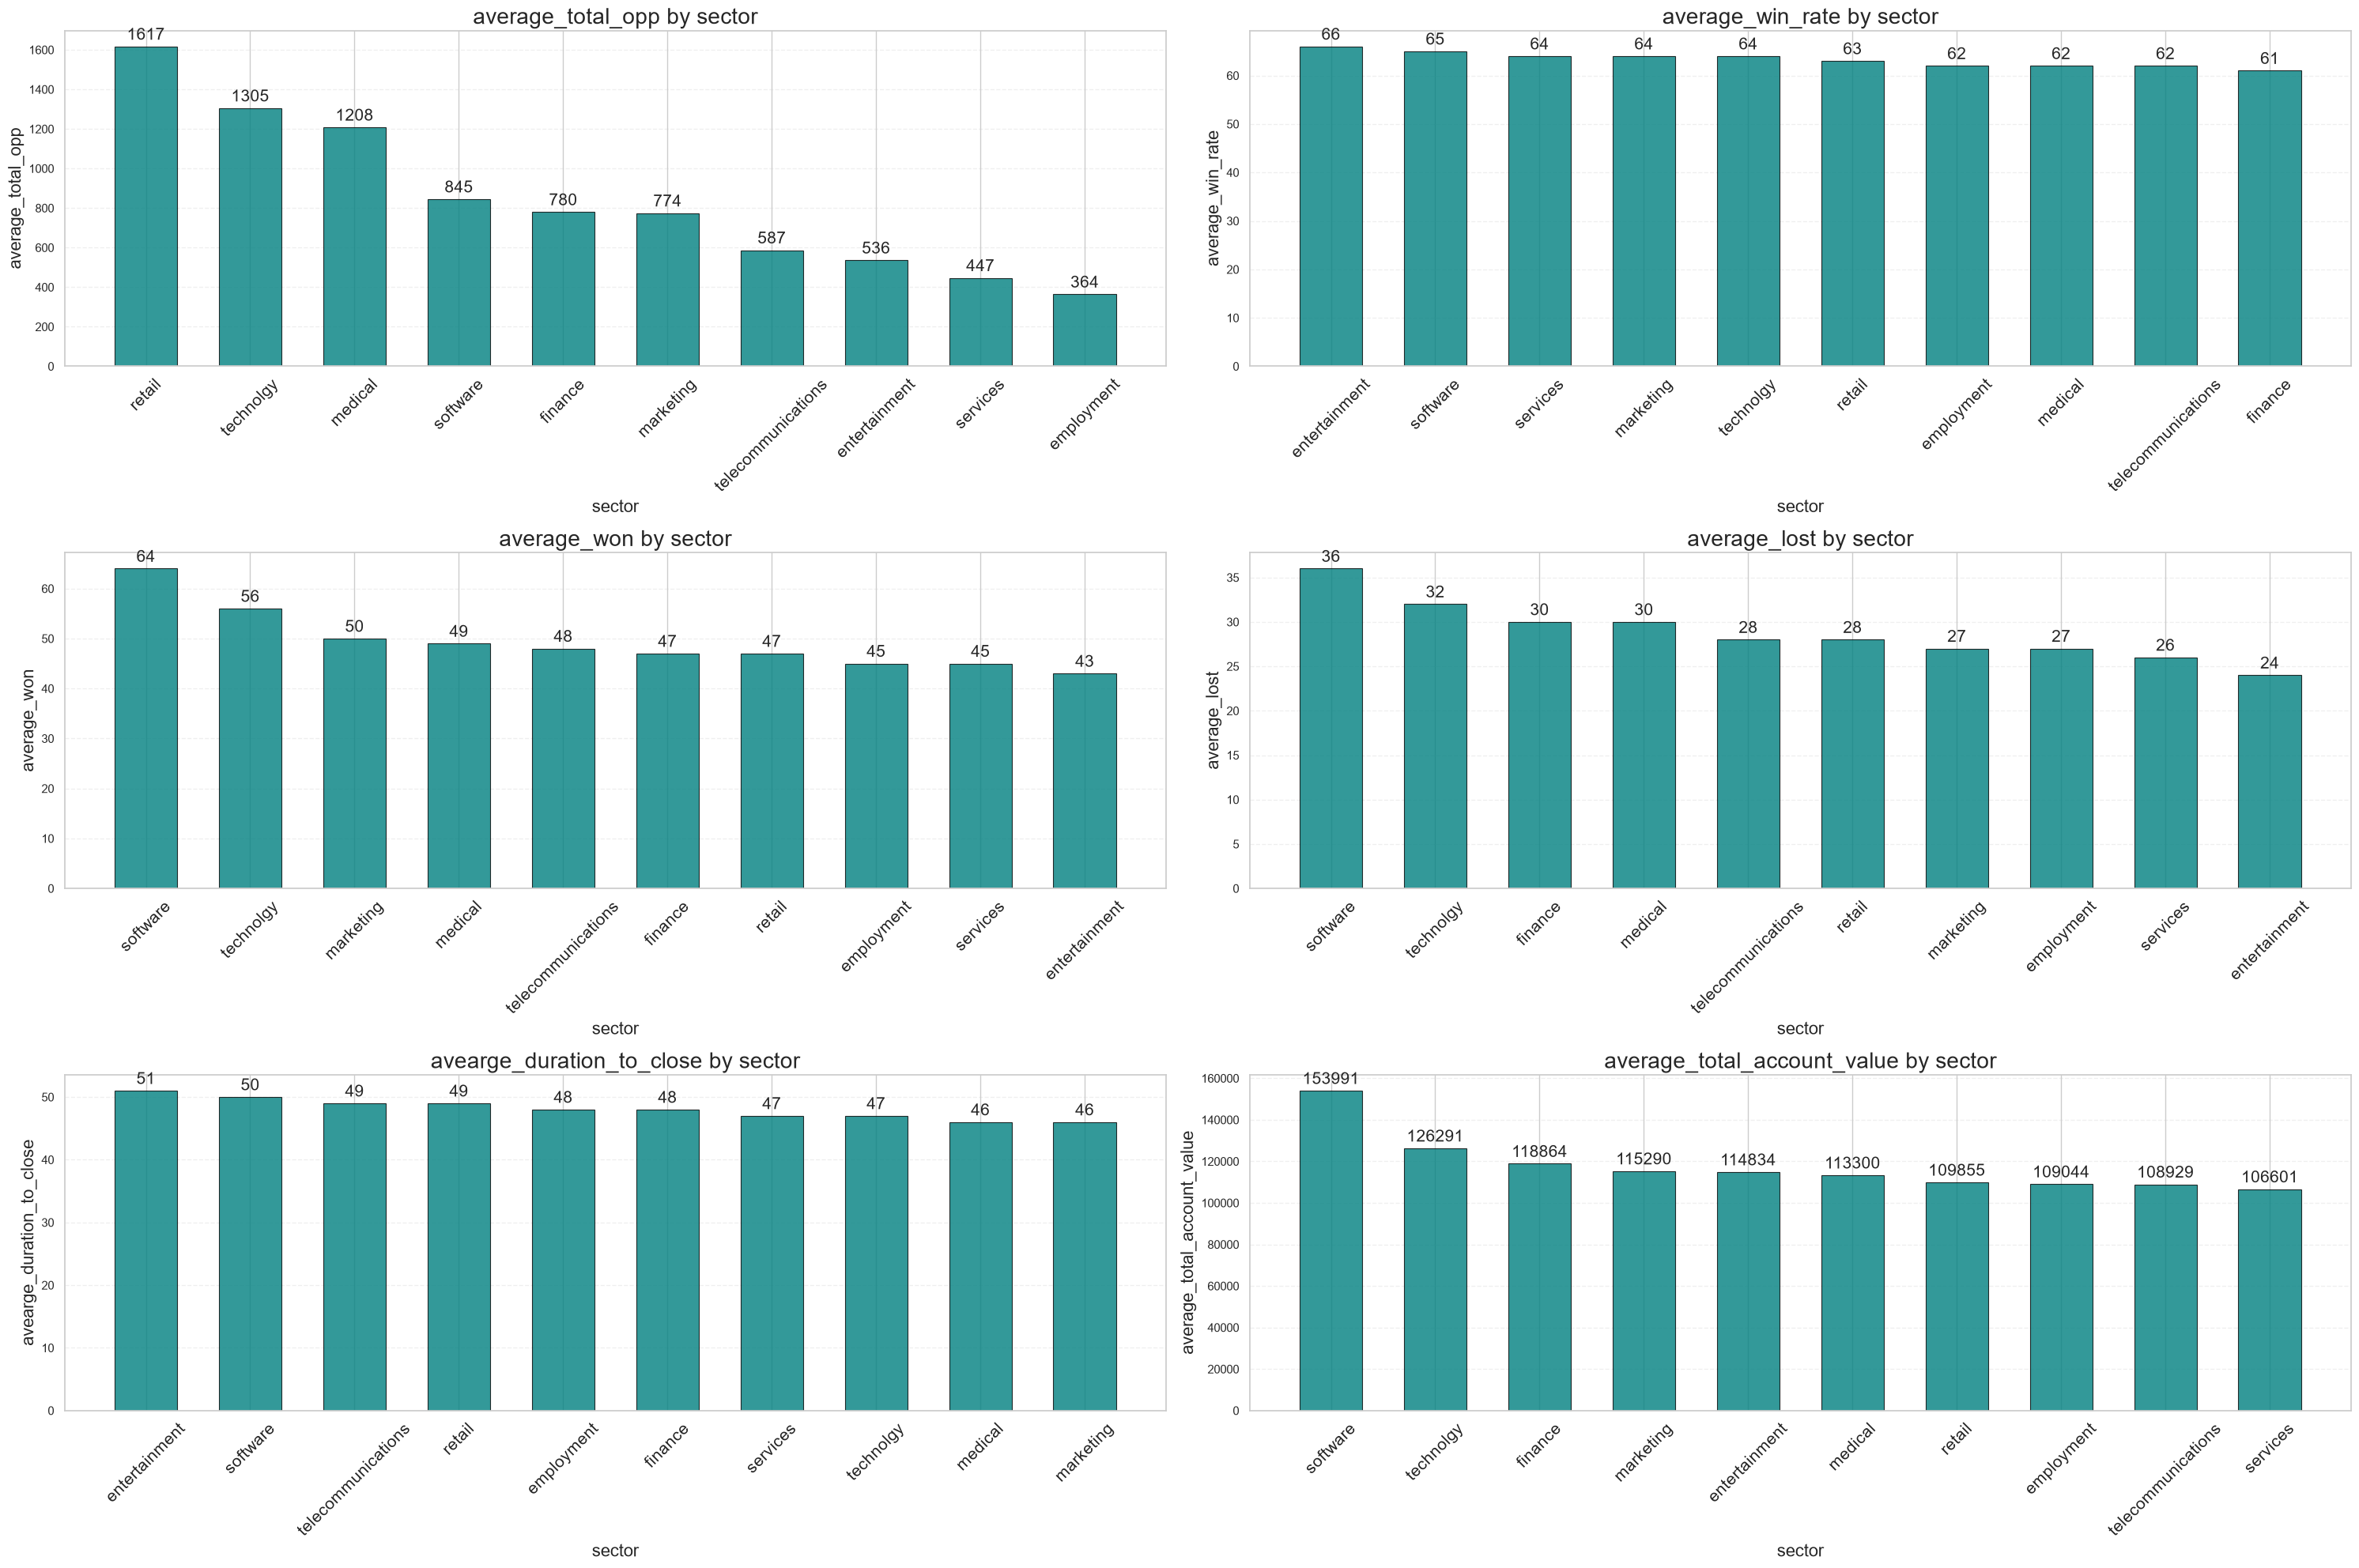

In [122]:
breakdown_bar(df_account_char,'sector')

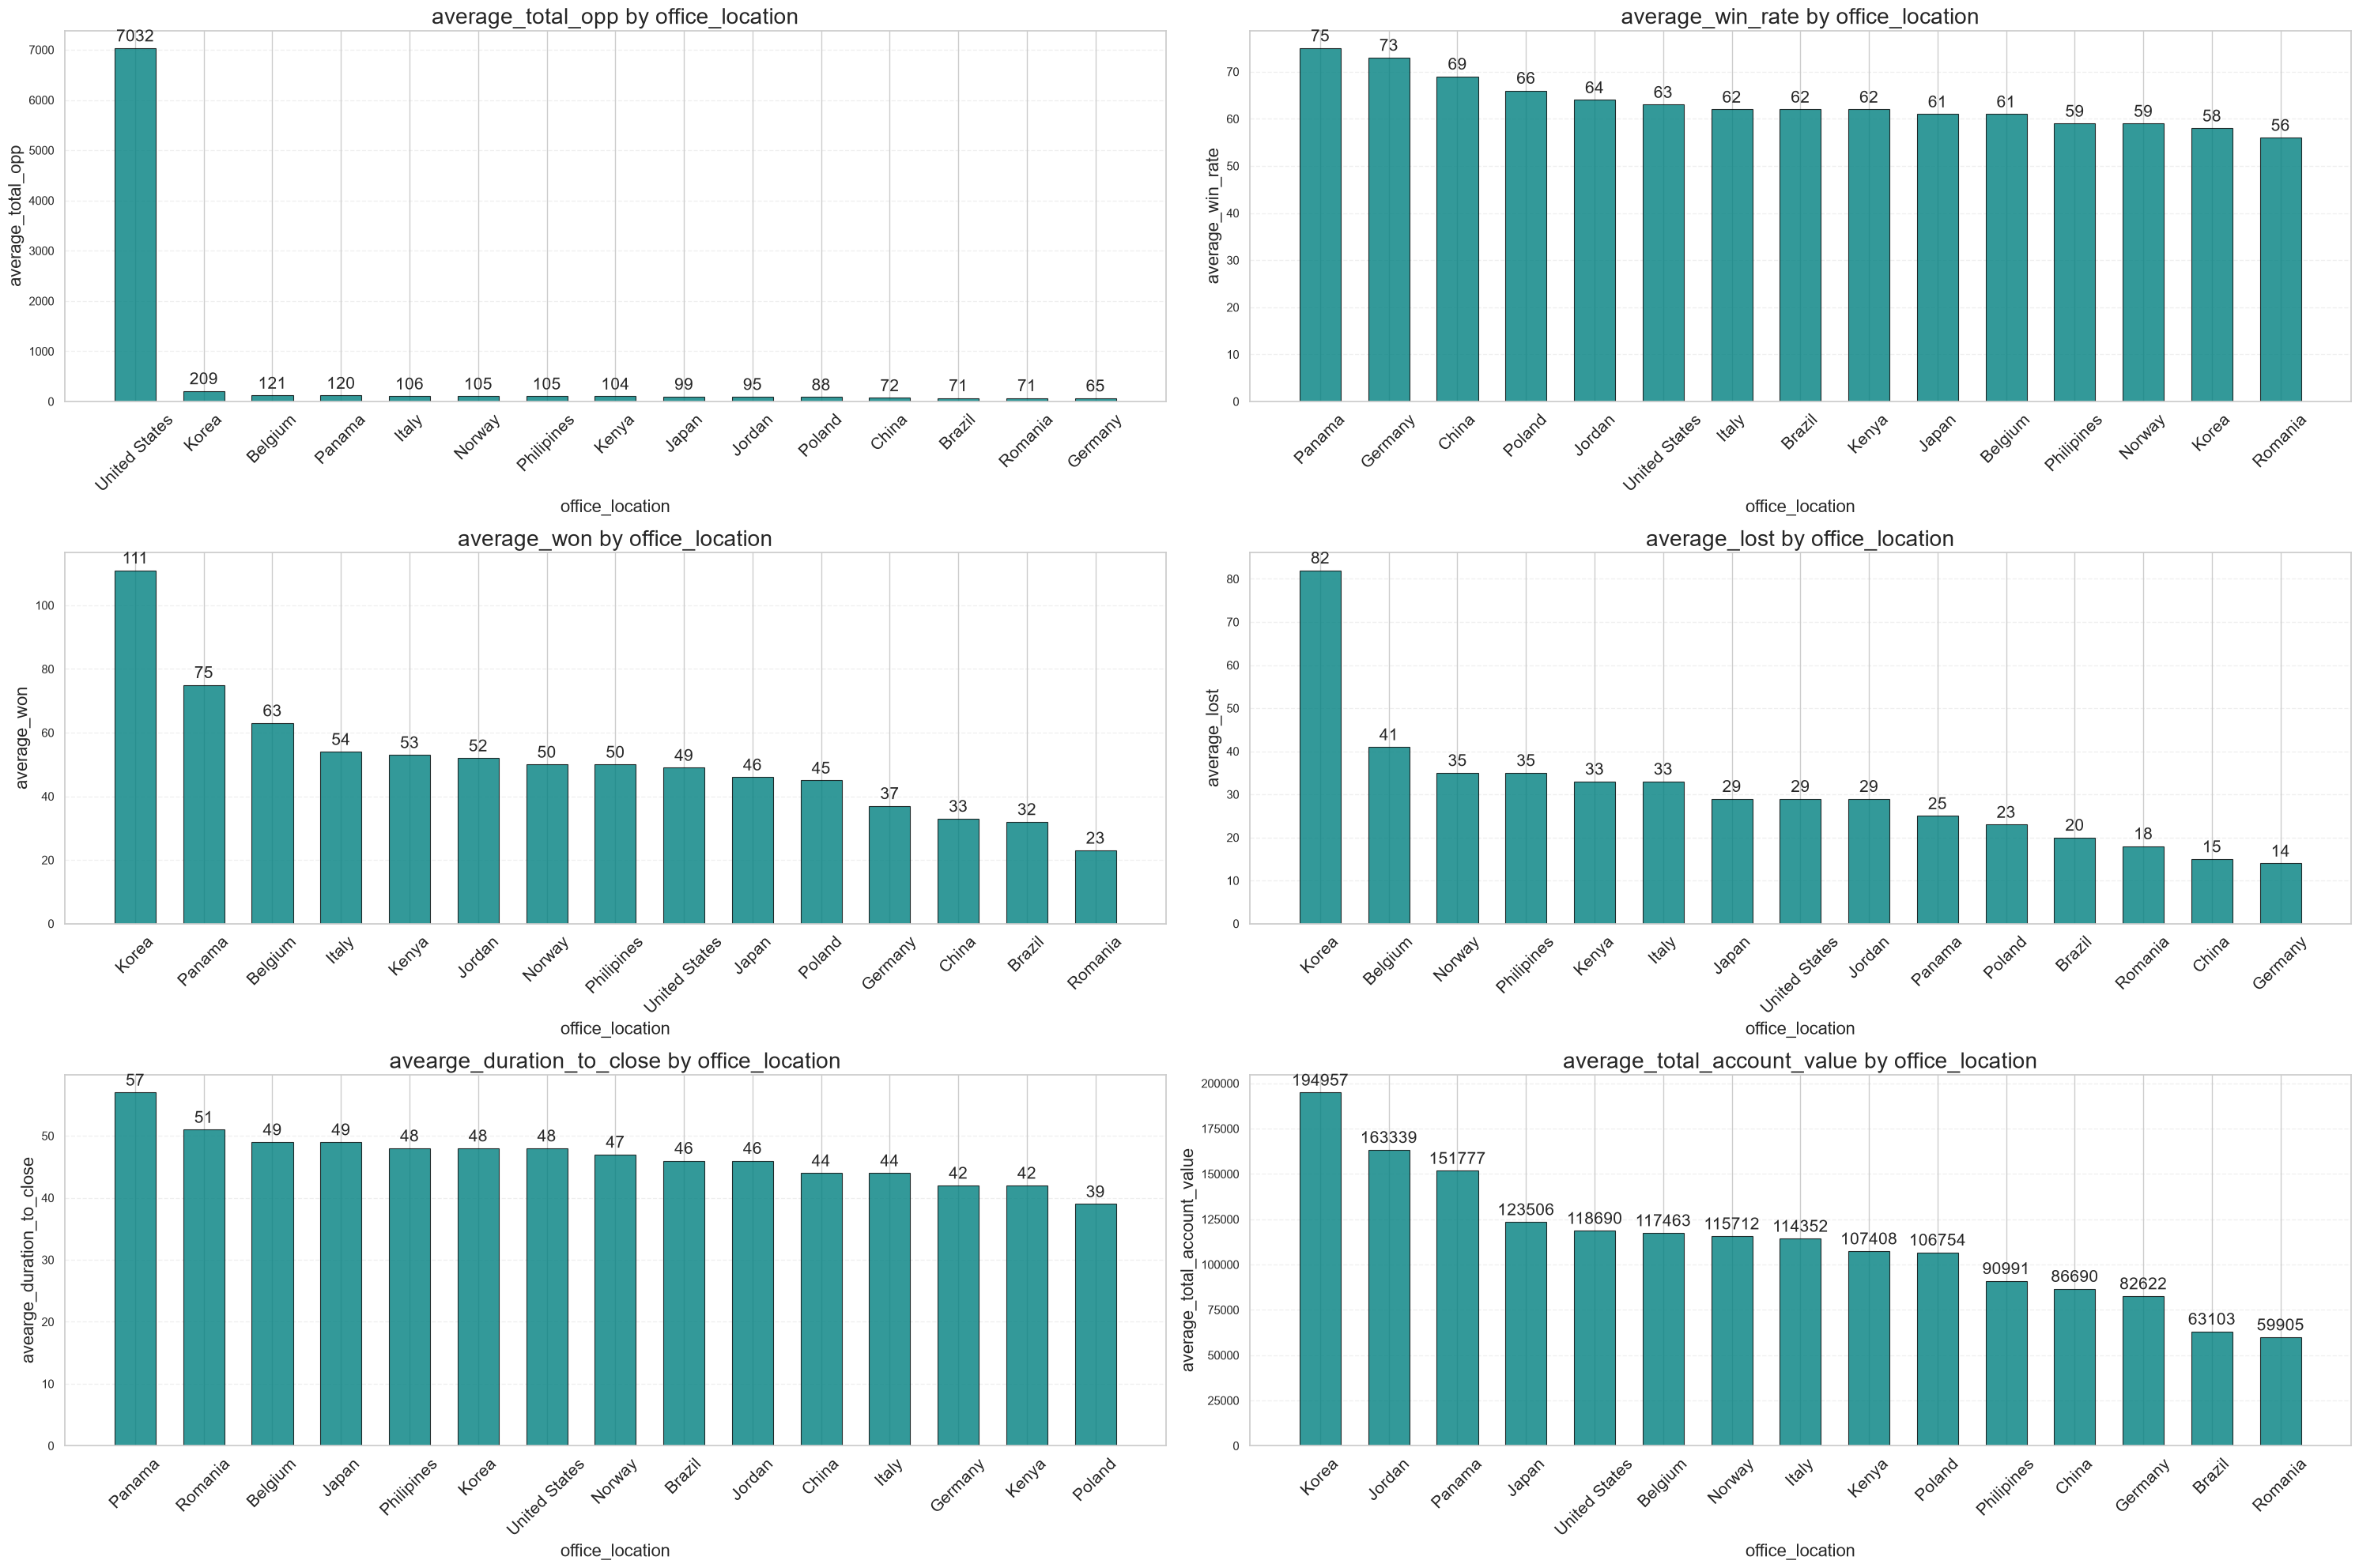

In [123]:
breakdown_bar(df_account_char,'office_location')

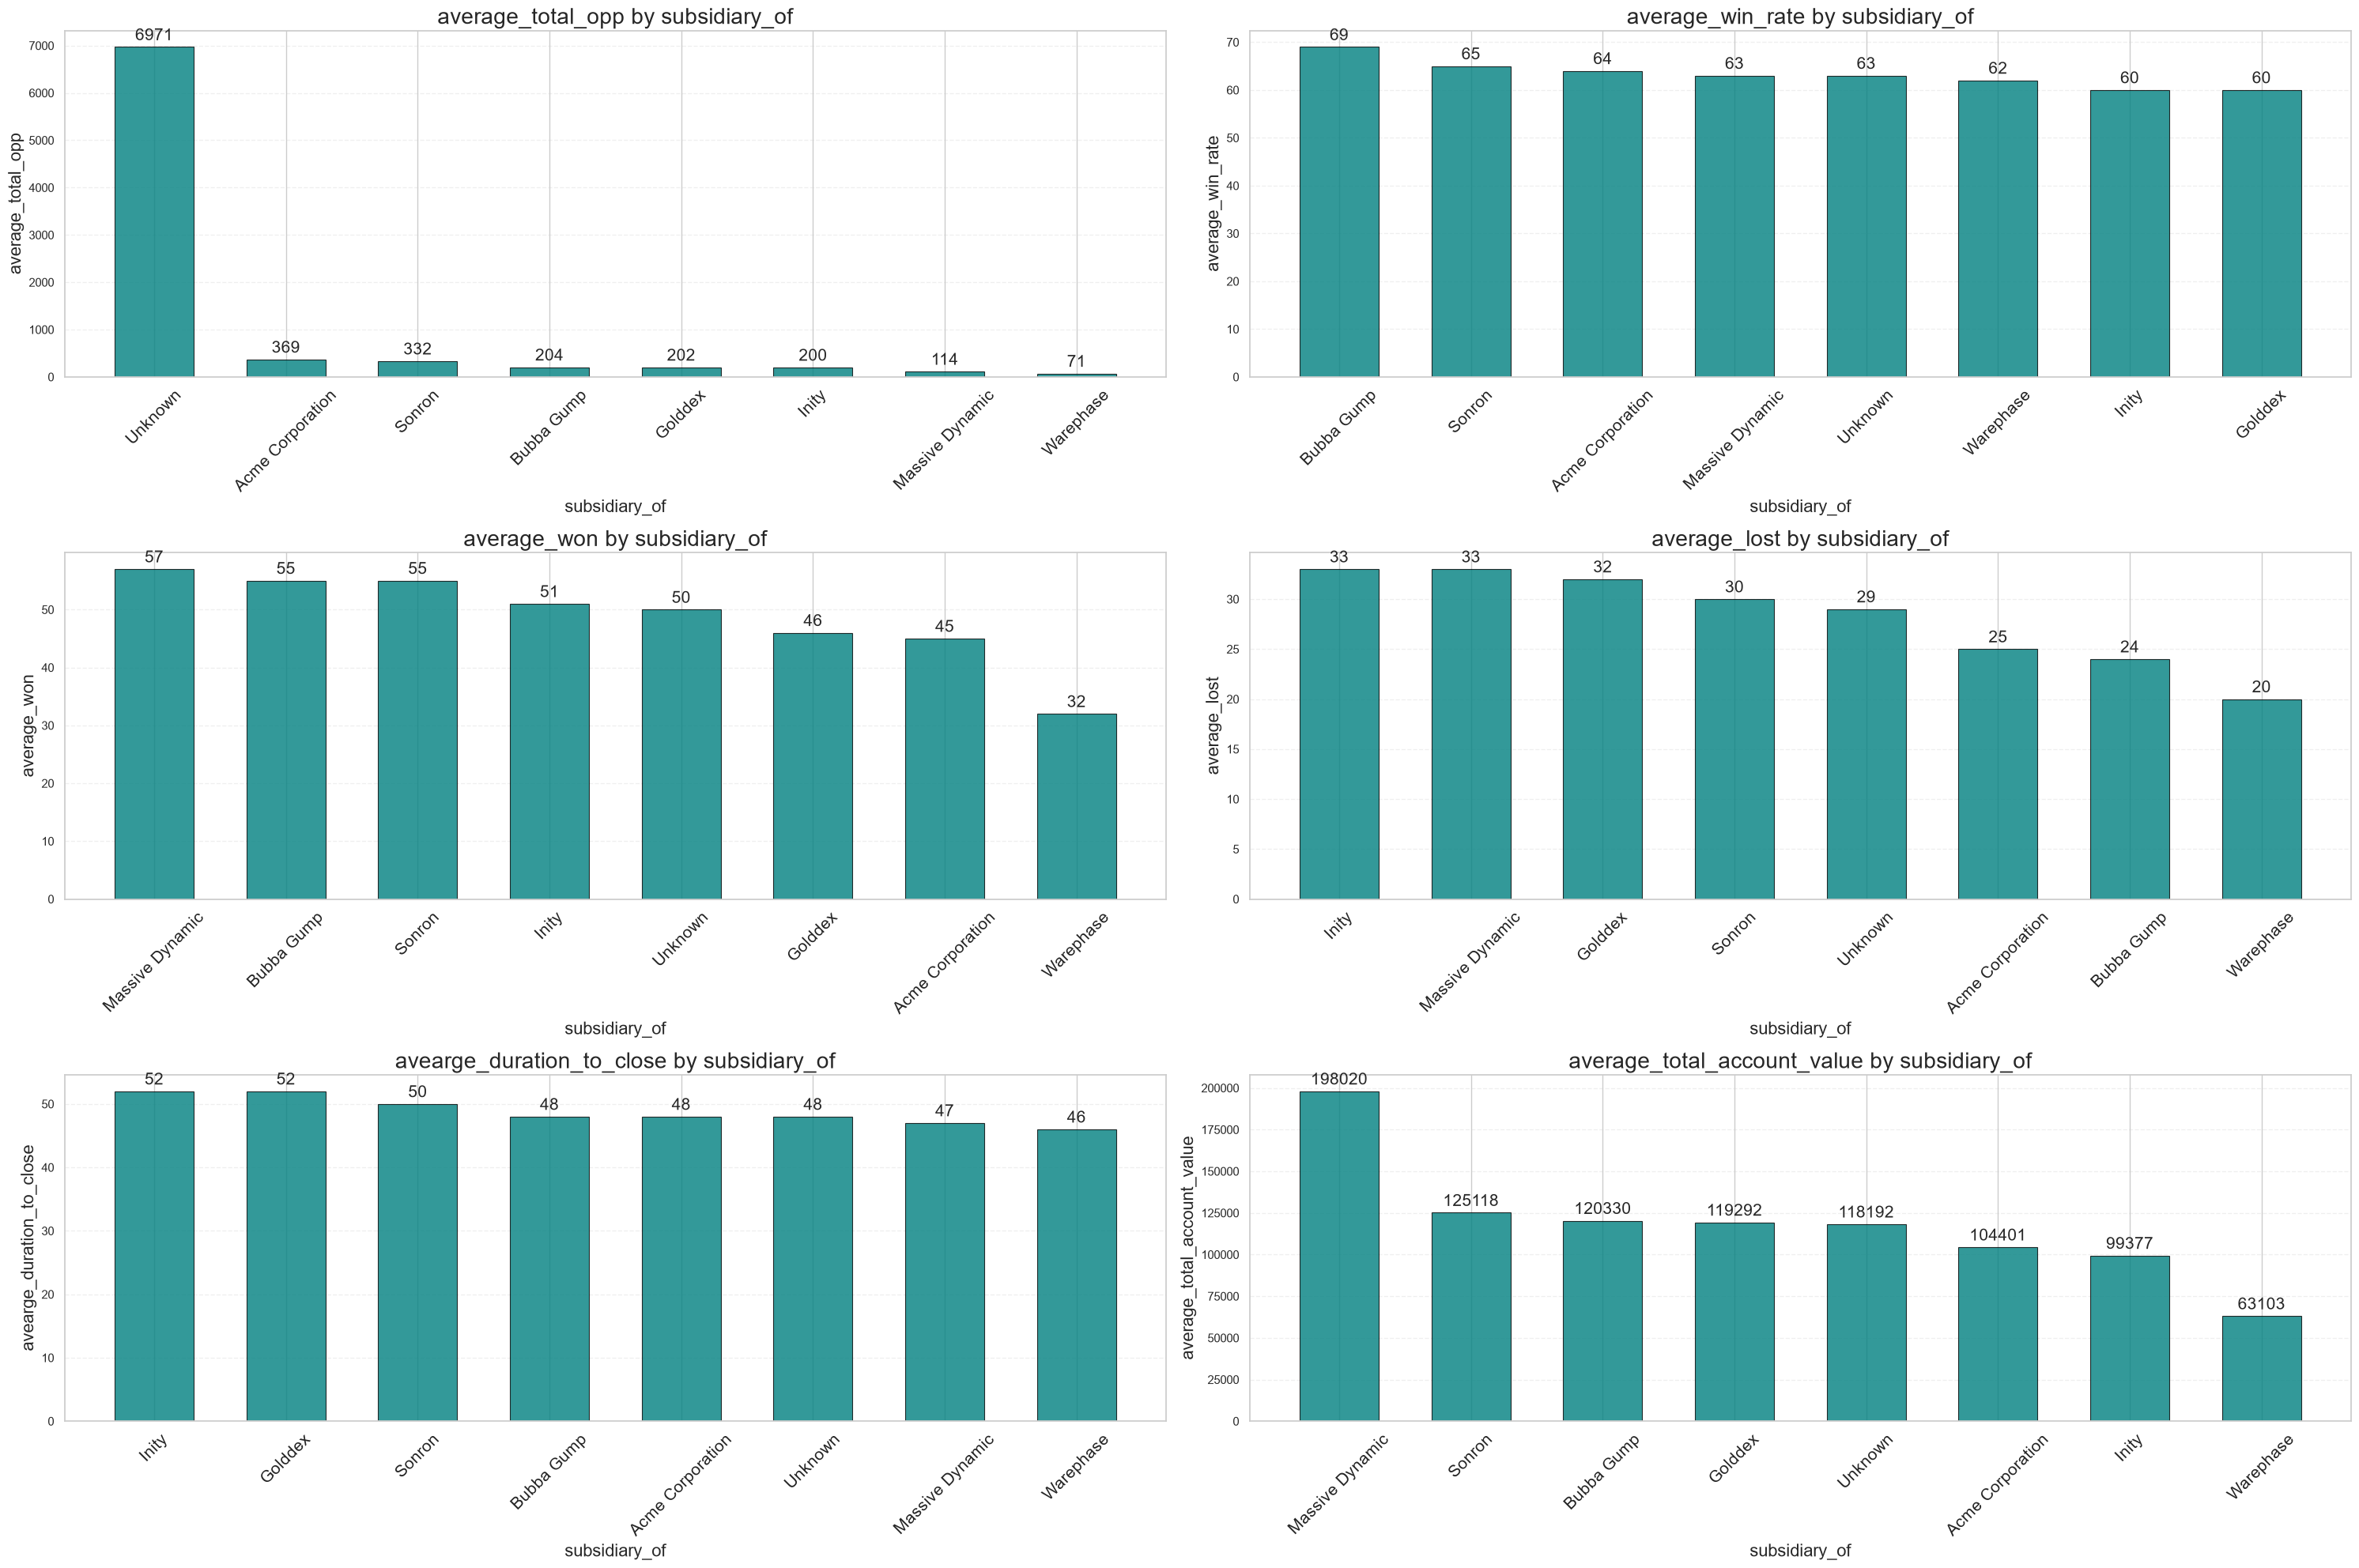

In [124]:
breakdown_bar(df_account_char,'subsidiary_of')

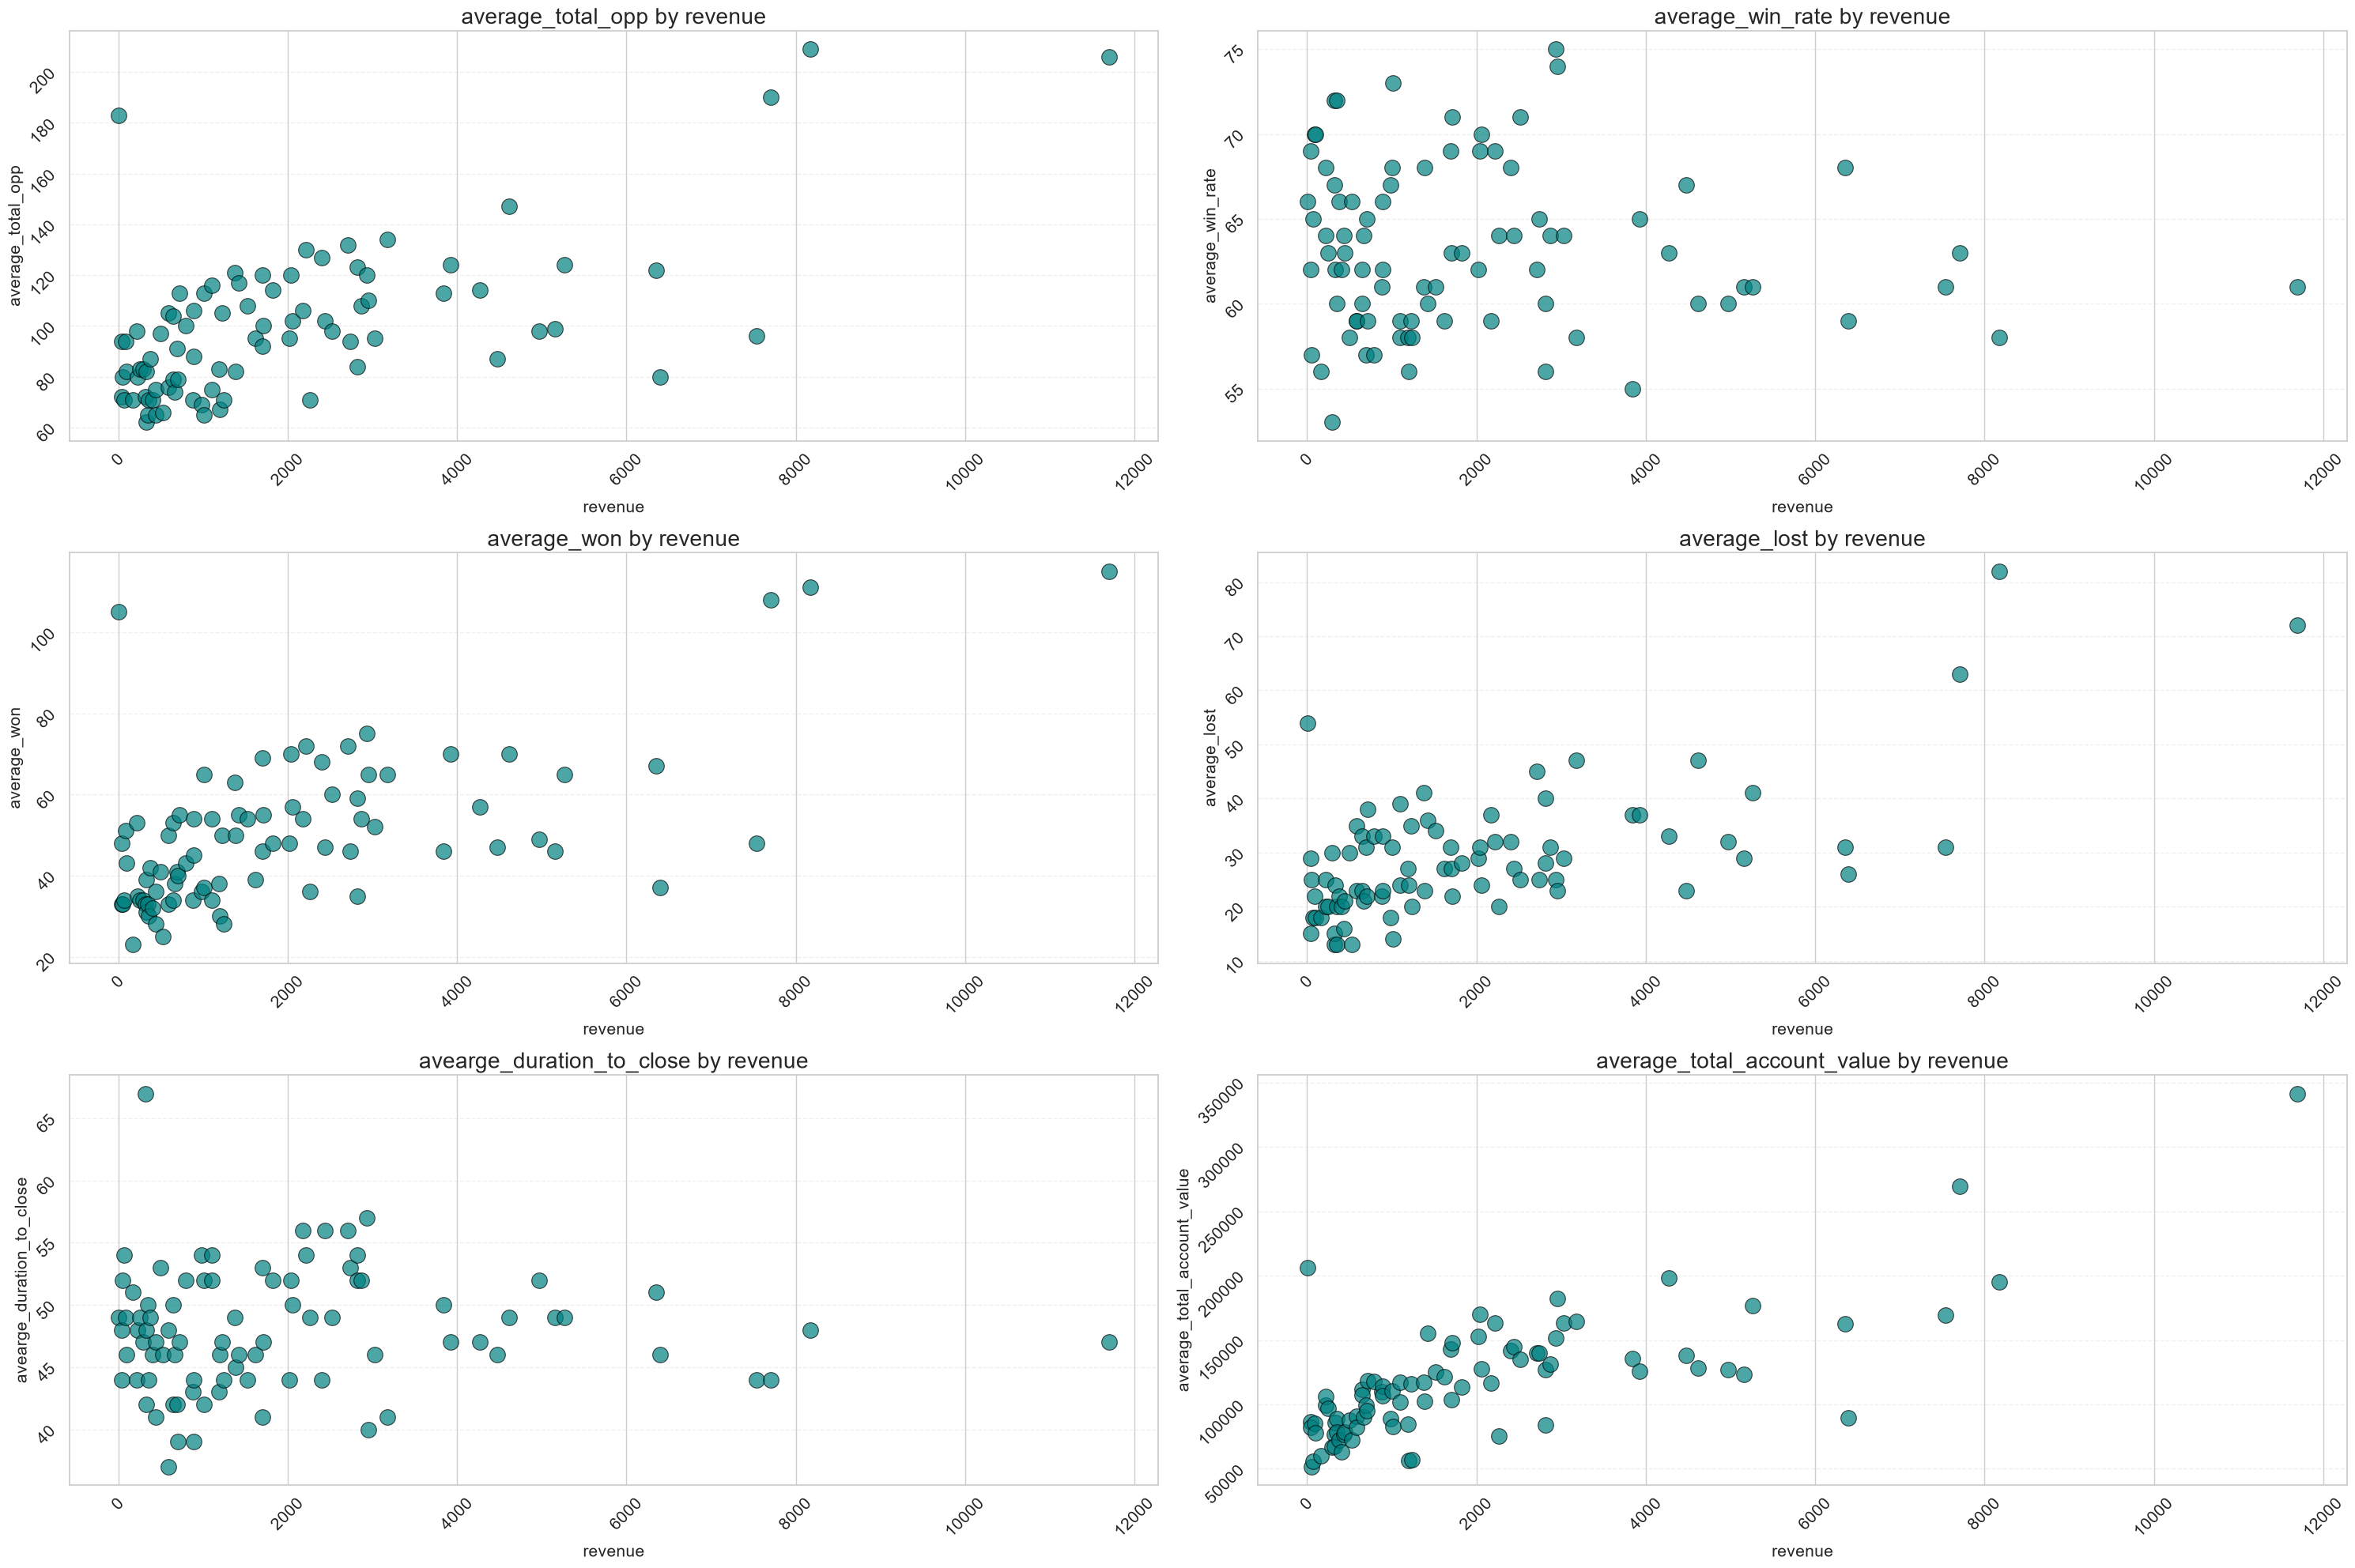

In [125]:
breakdown_plot(df_account_char,'revenue')

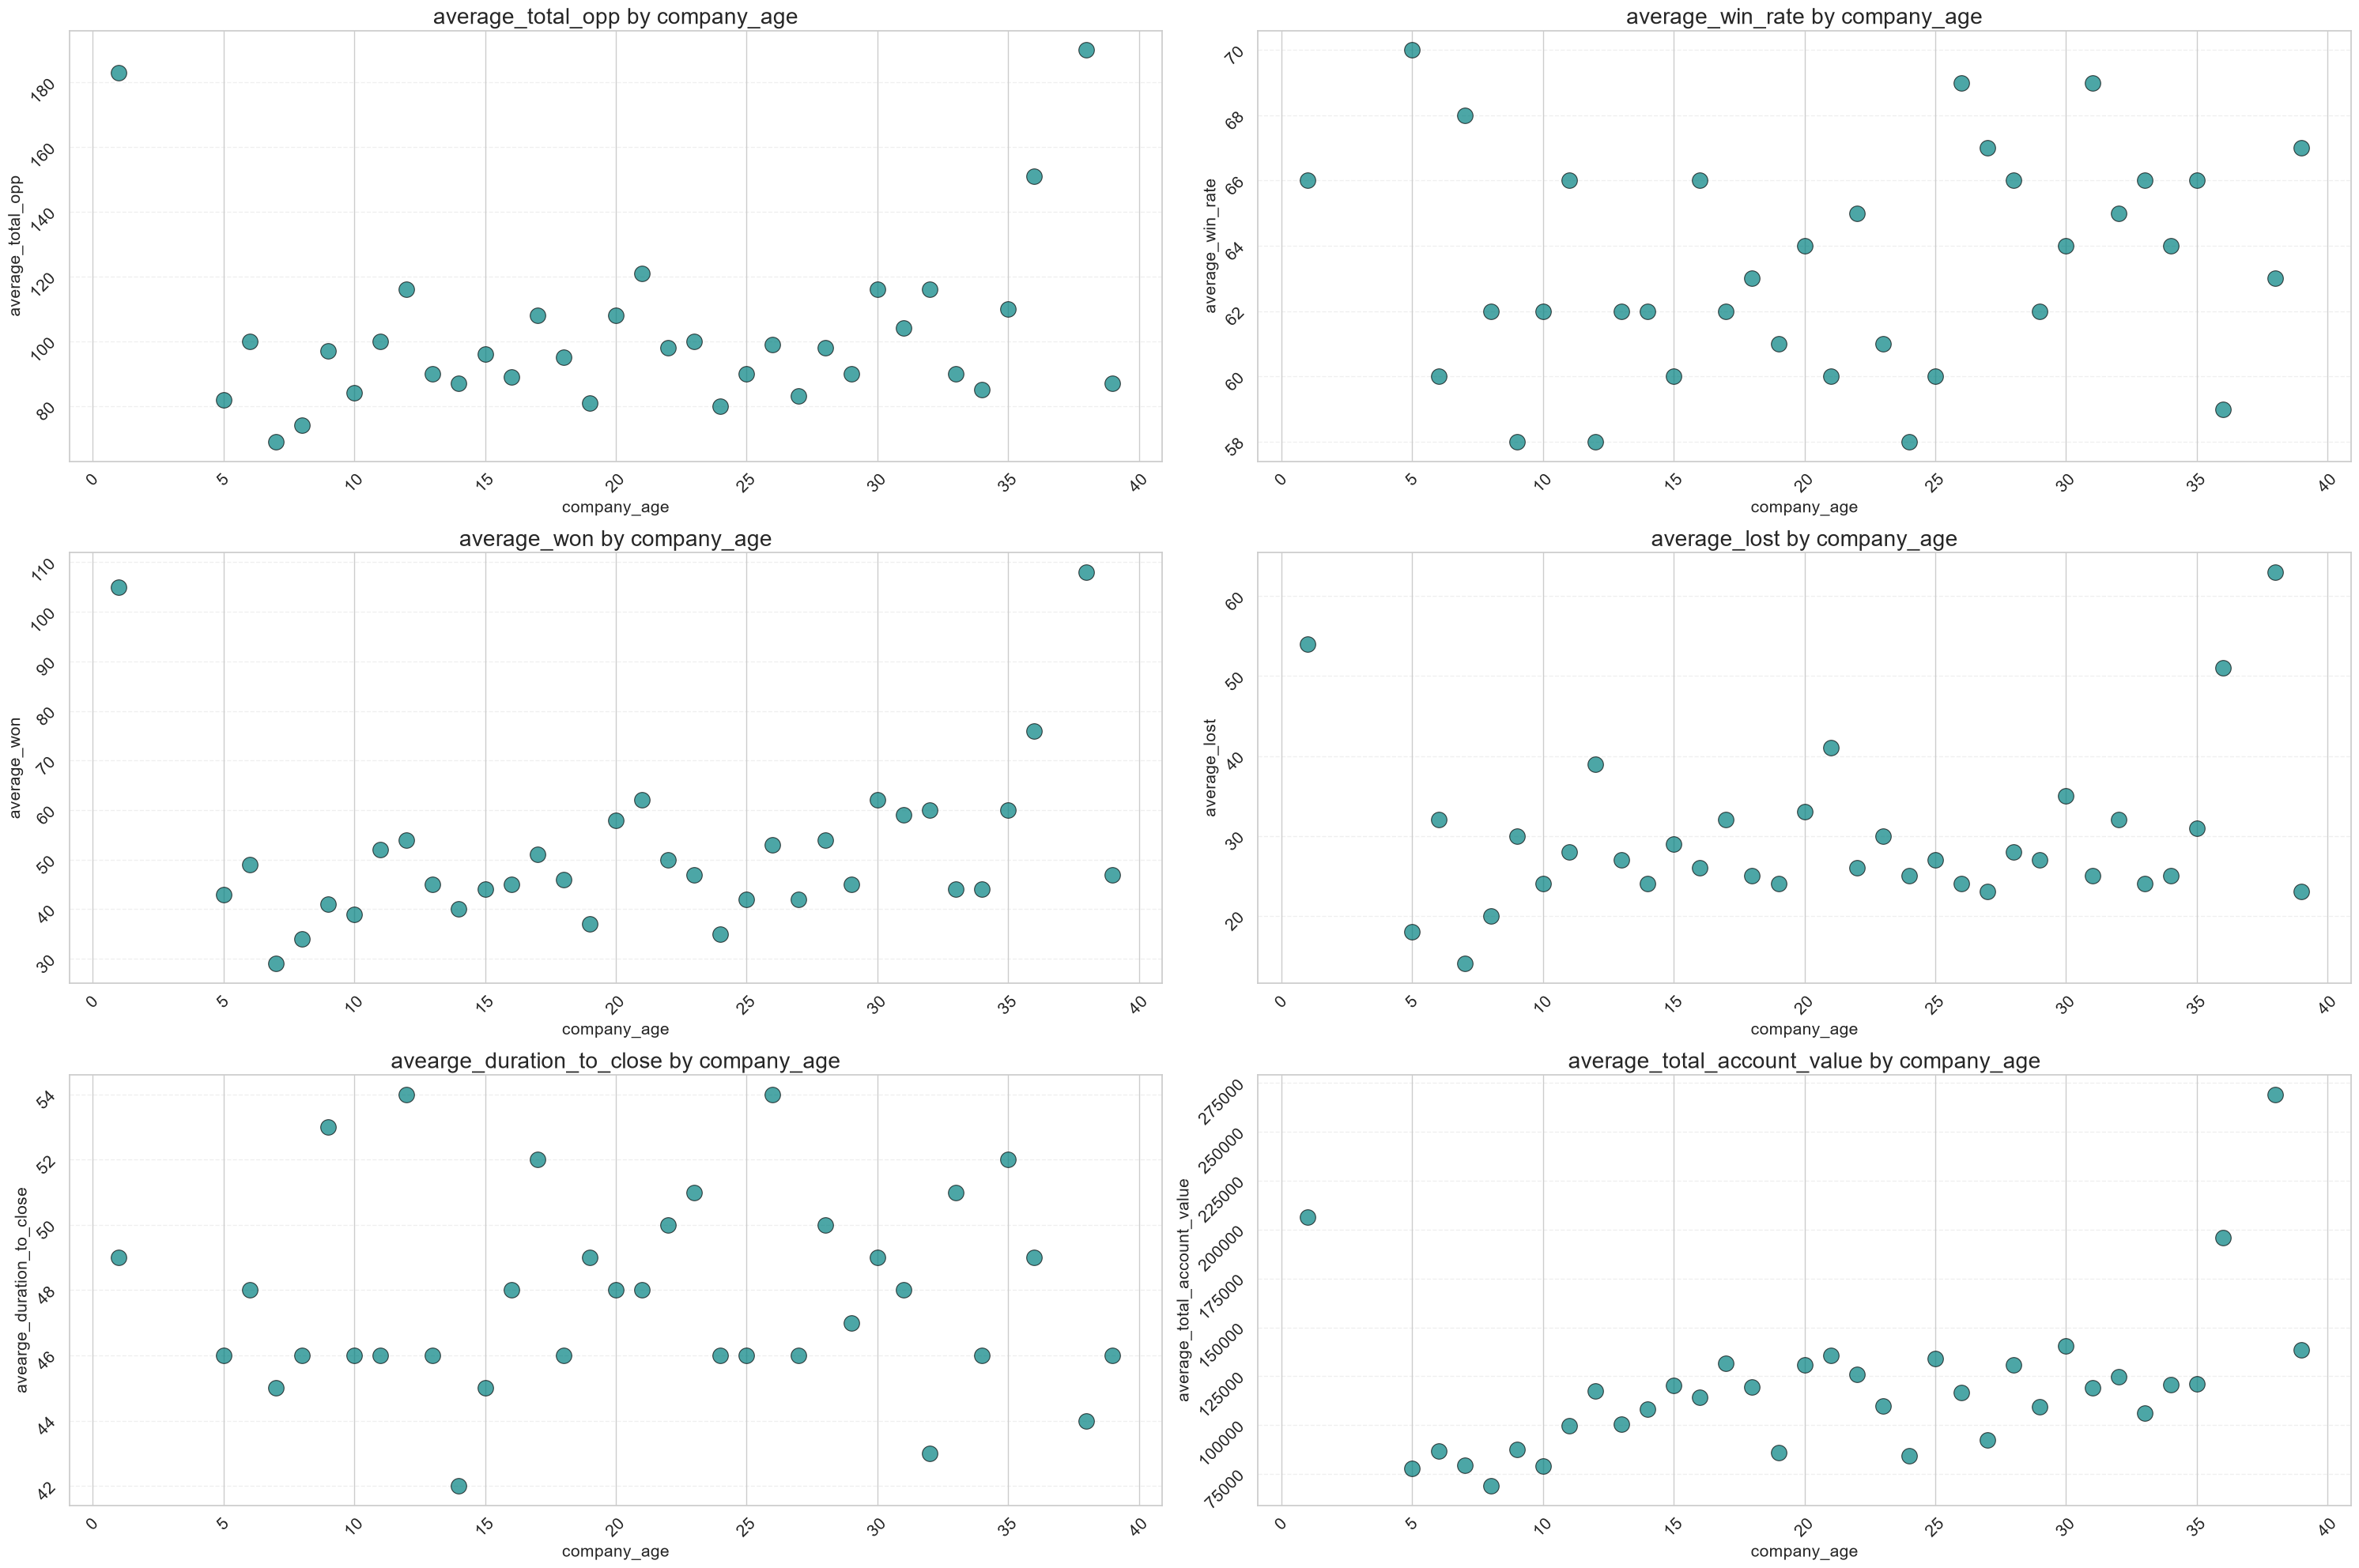

In [126]:
breakdown_plot(df_account_char,'company_age')

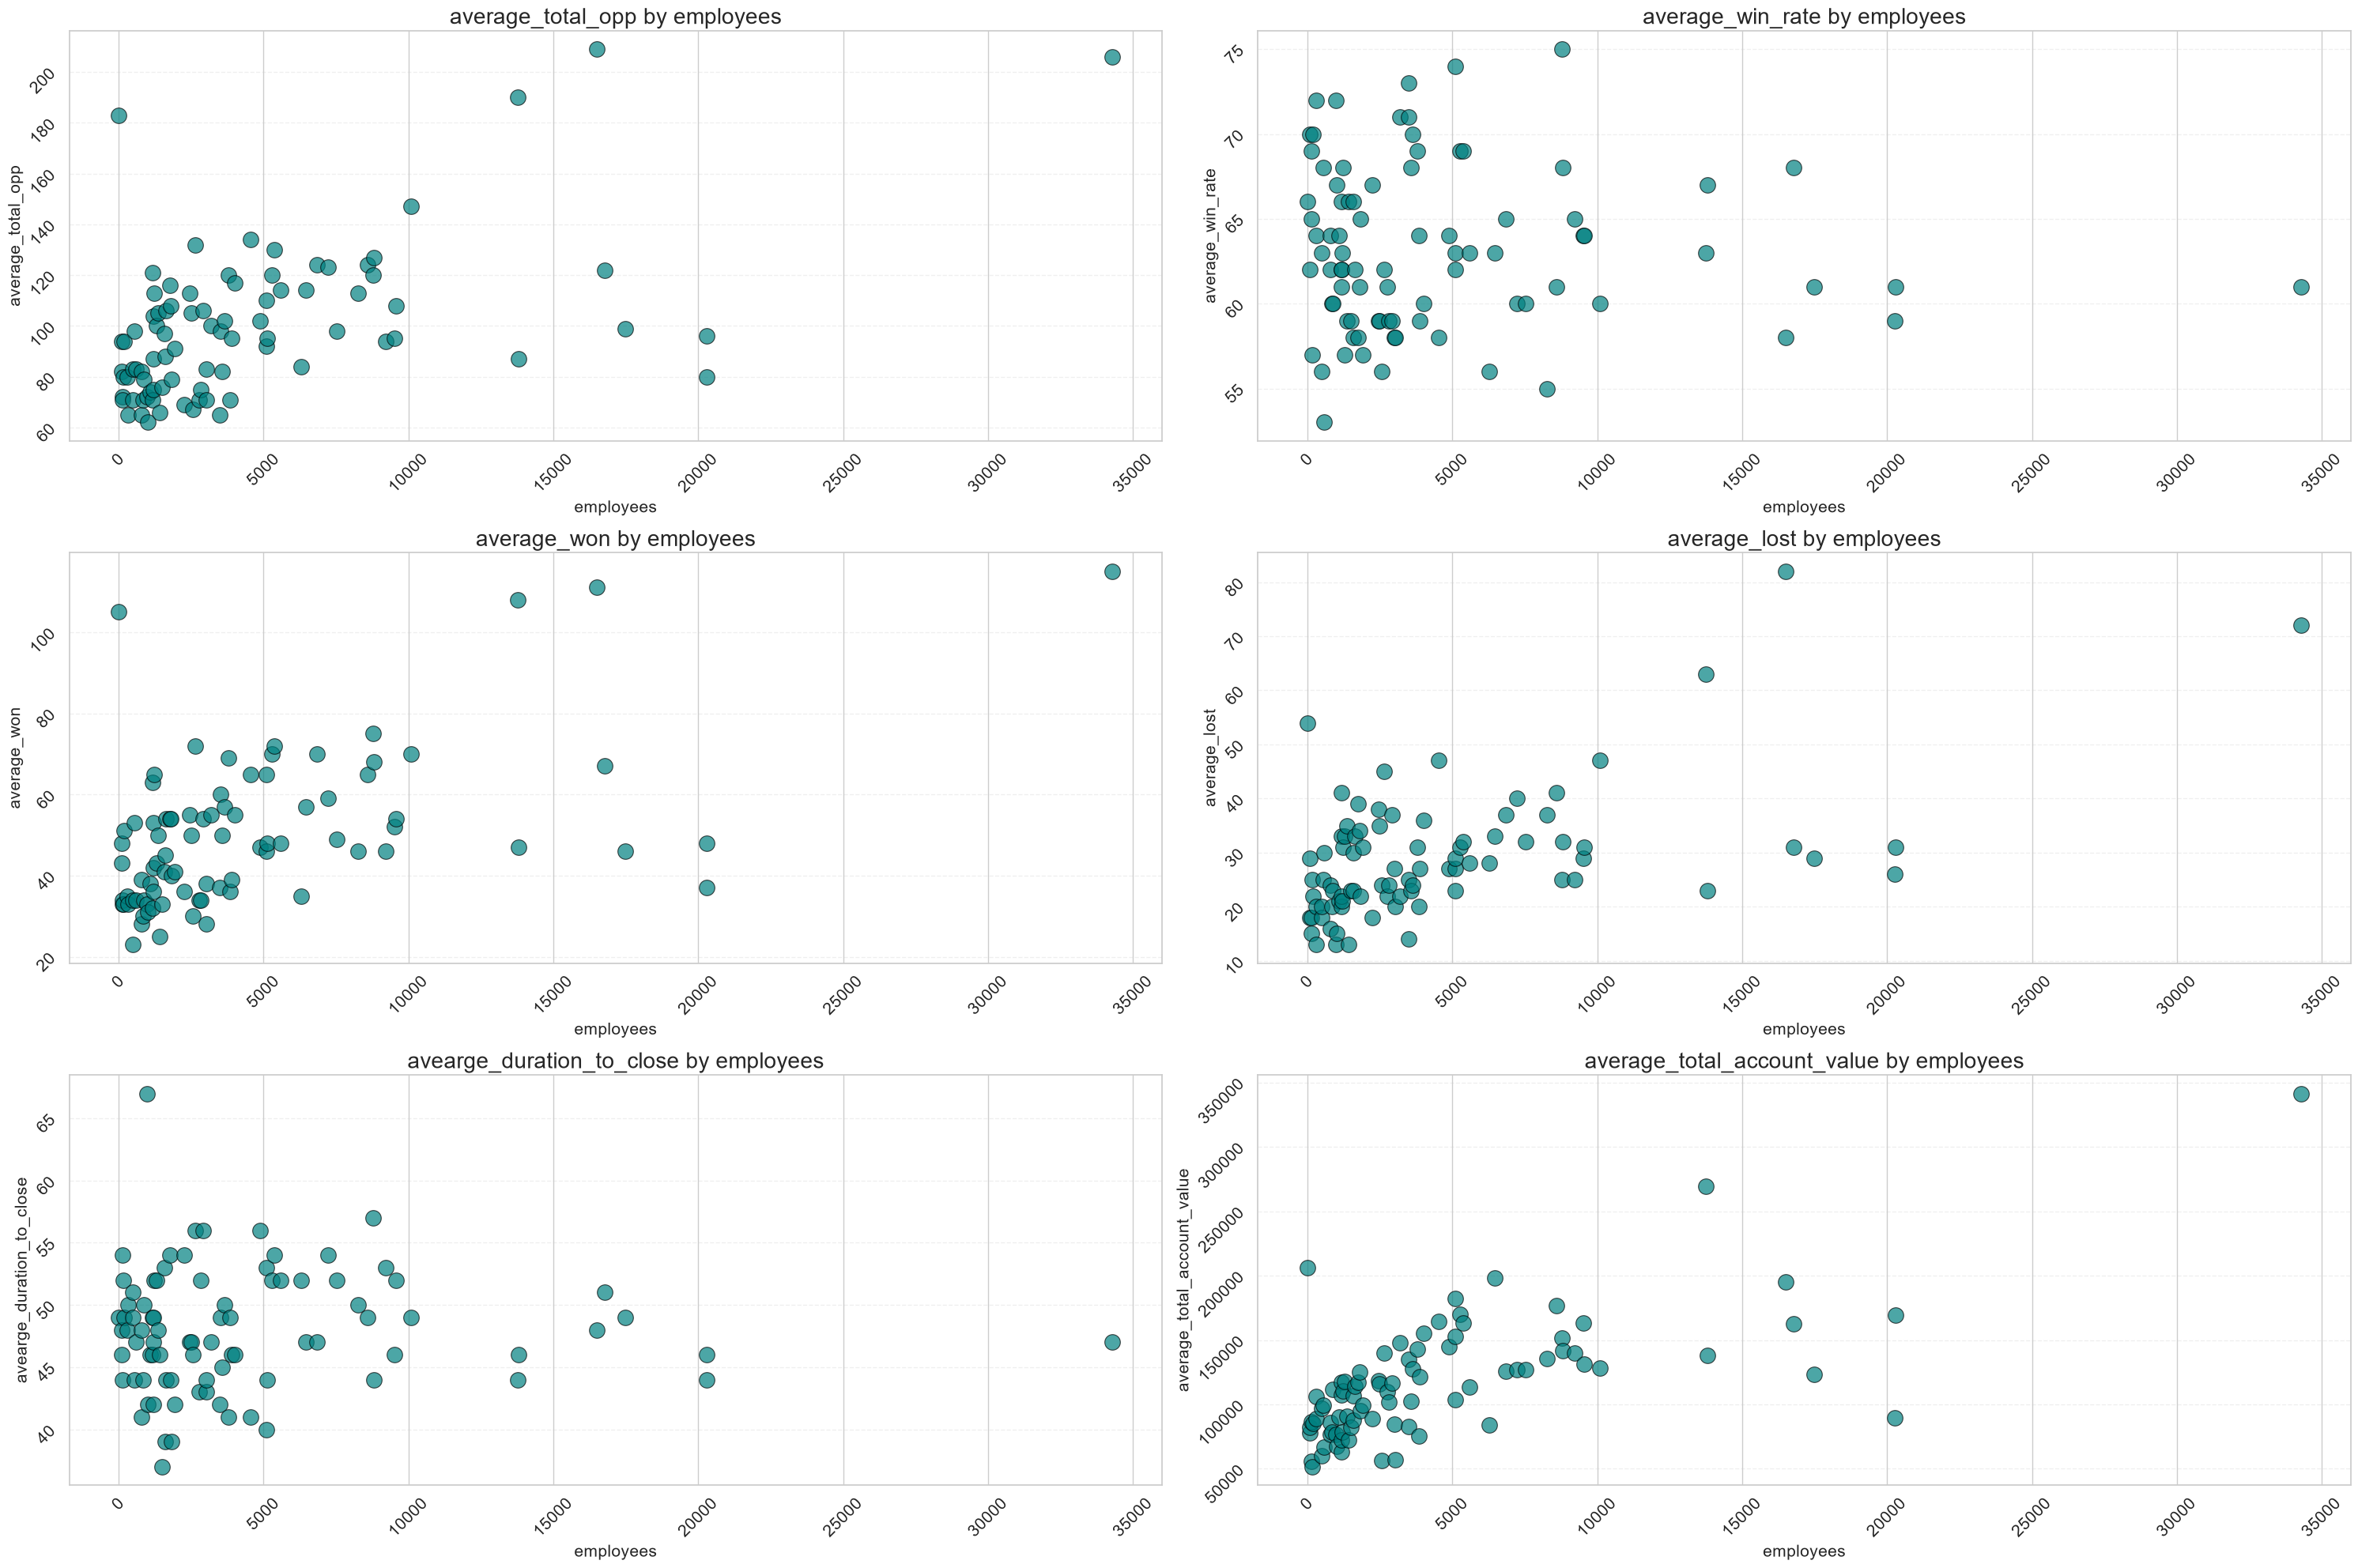

In [127]:
breakdown_plot(df_account_char,'employees')

In [128]:
df_account_char.head()

,account,sector,year_established,revenue,employees,office_location,subsidiary_of,total_opportunity,won,lost,avg_duration_to_close,account_value,win_rate,company_age
0,Acme Corporation,technolgy,1996,1100.04,2822,United States,Unknown,75,34,24,52.0,101744.0,59.0,22
1,Betasoloin,medical,1999,251.41,495,United States,Unknown,83,34,20,49.0,97036.0,63.0,19
2,Betatech,medical,1986,647.18,1185,Kenya,Unknown,104,53,33,42.0,107408.0,62.0,32
3,Bioholding,medical,2012,587.34,1356,Philipines,Unknown,105,50,35,48.0,90991.0,59.0,6
4,Bioplex,medical,1991,326.82,1016,United States,Unknown,62,31,15,42.0,67393.0,67.0,27


> SQL seperti apa yang perlu dievaluasi kembali?

In [129]:
value_threshold = df_accounts_summary['account_value'].median()
win_threshold = df_accounts_summary['win_rate'].median()
duration_threshold = df_accounts_summary['avg_duration_to_win'].median()

conditions = [
  
    (
        (df_accounts_summary['account_value'] >= value_threshold) &
        (df_accounts_summary['win_rate'] >= win_threshold) &
        (df_accounts_summary['avg_duration_to_win'] <= duration_threshold)
    ),

   
    (
        (df_accounts_summary['account_value'] >= value_threshold) &
        (df_accounts_summary['win_rate'] < win_threshold)
    ),

   
    (
        (df_accounts_summary['account_value'] < value_threshold) &
        (df_accounts_summary['win_rate'] >= win_threshold) &
        (df_accounts_summary['avg_duration_to_win'] <= duration_threshold)
    ),

   
    (
        (df_accounts_summary['account_value'] < value_threshold) &
        (df_accounts_summary['win_rate'] < win_threshold) &
        (df_accounts_summary['avg_duration_to_win'] > duration_threshold)
    ),

    
    (
        (df_accounts_summary['account_value'] >= value_threshold) &
        (df_accounts_summary['win_rate'] >= win_threshold) &
        (df_accounts_summary['avg_duration_to_win'] > duration_threshold)
    ),

    
    (
        (df_accounts_summary['account_value'] < value_threshold) &
        (df_accounts_summary['win_rate'] >= win_threshold) &
        (df_accounts_summary['avg_duration_to_win'] > duration_threshold)
    )
]

categories = [
    'Top Performing Accounts',
    'High-Value, Low-Conversion Accounts',
    'Efficient Accounts',
    'Underperforming Accounts',
    'High-Value, Slow-Closing Accounts',
    'Low-Value, Slow-Closing Accounts'
]

df_accounts_summary['performance_segment'] = np.select(
    conditions,
    categories,
    default='Underperforming Accounts'
)

| Segment | Account Value | Win Rate | Duration |
|---|---|---|---|
| Top Performing | High | High | Fast |
| High-Value, Low-Conversion | High | Low | Any |
| Efficient | Low | High | Fast |
| High-Value, Slow-Closing | High | High | Slow |
| Low-Value, Slow-Closing | Low | High | Slow |
| Underperforming | Low | Low | Slow |

> Potential Client, lihat dari jumlah opprtunity yang berhasil won, valuenya, berapa lama dari engagesampai jadi won